<div align="center">

# 🧠 DAY 02 — MODERN TOKENIZATION
### From Raw Text to Token IDs · Context Windows · Conversation Memory

**AI ENGINEERING MASTERCLASS**  |  **CORE TRACK**  |  **Hands-On Jupyter Lab**

![Python](https://img.shields.io/badge/Python-3.11%2B-3776AB?style=for-the-badge&logo=python&logoColor=white) ![Jupyter](https://img.shields.io/badge/Jupyter-Notebook-F37626?style=for-the-badge&logo=jupyter&logoColor=white) ![tiktoken](https://img.shields.io/badge/Tokenizer-tiktoken-152238?style=for-the-badge) ![Level](https://img.shields.io/badge/Level-Fundamentals-16A085?style=for-the-badge)

**A visual, practical introduction to the token economics behind modern LLM applications.**

*No paid API is required for Labs 1–10. The last live-model experiment is optional.*

</div>

---

> **The central idea:** Language models do not see text the way humans do. A tokenizer converts text into token IDs. Tokenization affects **input length, context fit, latency, cost, and memory design**.

**Reference adaptation:** This lesson expands the supplied `day4.ipynb` examples (token IDs and conversation history), adding modern tokenizer comparisons and engineering exercises. Tokens and memory are connected but different ideas.

## 🧭 Learning path

| Lab | Topic | Deliverable |
|:---:|---|---|
| 01 | Setup & tokenizer selection | Working `tiktoken` encoder |
| 02 | Text → tokens → IDs | Inspect token IDs and token pieces |
| 03 | Why tokens are not words | Compare sample phrases |
| 04 | Unicode & multilingual text | Inspect raw token bytes safely |
| 05 | Compare tokenizer vocabularies | `cl100k_base` vs `o200k_base` |
| 06 | Visual token map | Color-coded token segmentation |
| 07 | Build a reusable token analyzer | Production-friendly helpers |
| 08 | Context window & budget | Fit checks with output reserve |
| 09 | Cost & message overhead | An explicitly illustrative estimator |
| 10 | Conversation memory | Stateless API vs context replay |
| 11 | Optional live API | Inspect actual usage, if authorized |
| 12 | Challenges & recap | Exercises, tests and next steps |

**Prerequisites:** Python fundamentals, your Day 1 introduction to calling LLM APIs, and familiarity with notebooks.

## 00 — The mental model

```mermaid
flowchart LR
    A[Raw user text] --> B[Tokenizer / encoding]
    B --> C[Token IDs]
    C --> D[LLM context]
    D --> E[Predicted output token IDs]
    E --> F[Detokenized text]
```

**Three terms to distinguish:**

- **Token:** a model-facing unit of text or other content; text tokens can be full words, fragments, whitespace-plus-text, or punctuation.
- **Token ID:** an integer assigned by a *specific* vocabulary. The same text can have different IDs with different encodings.
- **Encoding/tokenizer:** the rules and vocabulary mapping between a string and token IDs. Many OpenAI text tokenizers use a byte-level BPE family of techniques; the complete procedure also involves text segmentation rules.

**Engineering takeaway:** Counting words or characters is not a reliable replacement for counting tokens. Tokenization can differ across models and languages.

## 01 — Setup

Run the installation command in your project terminal (not inside this notebook):

```powershell
uv add tiktoken matplotlib pandas
```

If you are **not** using `uv`:

```bash
python -m pip install tiktoken matplotlib pandas
```

Optional live API exercise (only if you choose to run Lab 11):

```powershell
uv add openai python-dotenv
```

Select the project's virtual environment as your Jupyter kernel, then run the following cell. The first `tiktoken` encoding load can download tokenizer metadata; later encoding operations are local.

In [2]:
import sys
import tiktoken
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

print('Python:', sys.version.split()[0])
print('tiktoken:', getattr(tiktoken, '__version__', 'installed'))

MODEL = 'gpt-4.1-mini'  # familiar model from reference; tokenizer lookup can change with versions
try:
    enc = tiktoken.encoding_for_model(MODEL)
except KeyError:
    enc = tiktoken.get_encoding('o200k_base')
    print('Model not mapped by this tiktoken version; using o200k_base explicitly.')
print('Selected encoding:', enc.name)

Python: 3.12.13
tiktoken: 0.14.0
Selected encoding: o200k_base


## 02 — Your first encoding

We'll retain the spirit of the original reference: tokenize a plain-English sentence, inspect every token, then decode it. **Do not assume each token is a complete word.**

In [3]:
sentence = 'Hi my name is Ed and I like banoffee pie'
token_ids = enc.encode(sentence)
print('Original text:', sentence)
print('Token IDs:', token_ids)
print('Token count:', len(token_ids))
print('Exact round trip:', enc.decode(token_ids) == sentence)

Original text: Hi my name is Ed and I like banoffee pie
Token IDs: [12194, 922, 1308, 382, 6117, 326, 357, 1299, 9171, 26458, 5148]
Token count: 11
Exact round trip: True


In [4]:
rows = []
for position, token_id in enumerate(token_ids):
    raw = enc.decode_single_token_bytes(token_id)
    rows.append({'position': position, 'token_id': token_id,
                 'piece_preview': raw.decode('utf-8', errors='replace'),
                 'raw_utf8_bytes': repr(raw)})
display(pd.DataFrame(rows))

,position,token_id,piece_preview,raw_utf8_bytes
0,0,12194,Hi,b'Hi'
1,1,922,my,b' my'
2,2,1308,name,b' name'
3,3,382,is,b' is'
4,4,6117,Ed,b' Ed'
5,5,326,and,b' and'
6,6,357,I,b' I'
7,7,1299,like,b' like'
8,8,9171,ban,b' ban'
9,9,26458,offee,b'offee'


**Why bytes, rather than `decode([token_id])`?** A single token can represent only *part* of a multibyte UTF-8 character. Decoding it alone may display a replacement character (`�`). `decode_single_token_bytes()` exposes the exact bytes; decoding the **entire sequence** restores the original text.

## 03 — Tokens ≠ words ≠ characters

Whitespace, digits, code, casing, and uncommon spellings can all change segmentation. Test this rather than memorizing a tokens-per-word rule.

In [5]:
examples = [
    'Hello, world!',
    'hello world',
    'Tokenization is fascinating.',
    'antidisestablishmentarianism',
    '2 + 2 = 4',
    'def greet(name): return f"Hello {name}"',
    'https://github.com/venkatjs11/AI-Engineering-Masterclass',
    '   multiple   spaces',
]
summary = pd.DataFrame([
    {'text': text, 'characters': len(text), 'words_by_spaces': len(text.split()),
     'tokens': len(enc.encode(text))}
    for text in examples
])
display(summary)

,text,characters,words_by_spaces,tokens
0,"Hello, world!",13,2,4
1,hello world,11,2,2
2,Tokenization is fascinating.,28,3,5
3,antidisestablishmentarianism,28,1,6
4,2 + 2 = 4,9,5,7
5,"def greet(name): return f""Hello {name}""",39,5,11
6,https://github.com/venkatjs11/AI-Engineering-M...,56,1,16
7,multiple spaces,20,2,4


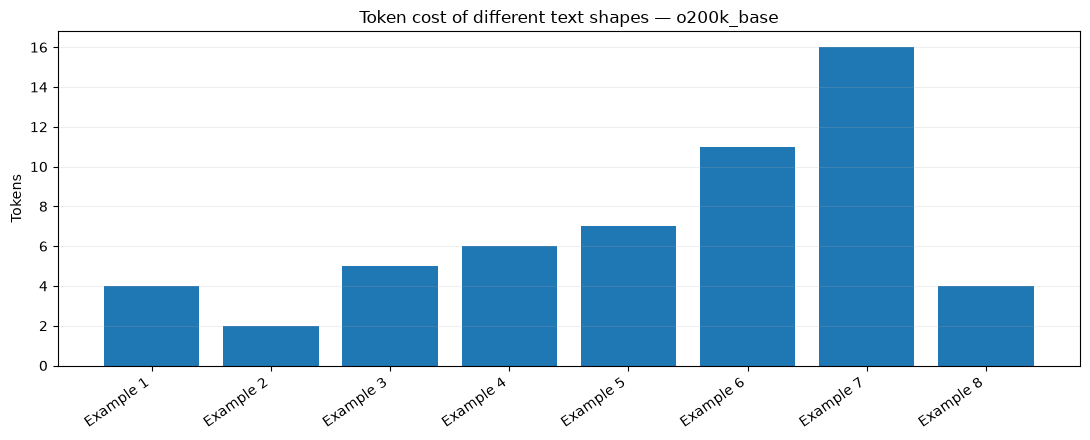

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
positions = list(range(len(summary)))
ax.bar(positions, summary['tokens'])
ax.set_xticks(positions, [f'Example {i+1}' for i in positions], rotation=35, ha='right')
ax.set_ylabel('Tokens')
ax.set_title(f'Token cost of different text shapes — {enc.name}')
ax.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.show()

**Check your intuition:** Why does punctuation matter? Why might URLs, code, and made-up words tokenize differently from frequent natural-language phrases? Tokenizer vocabulary reflects patterns seen during its construction, not a universal word dictionary.

## 04 — The Unicode reality check 🌍

Modern AI applications support international users, emojis, and mixed scripts. A tokenizer is generally byte-safe, but visible text and token boundaries need not coincide.

In [7]:
multilingual = [
    'Vanakkam! Welcome to Chennai.',
    'வணக்கம்! எப்படி இருக்கிறீர்கள்?',
    'नमस्ते, आप कैसे हैं?',
    '你好，世界！',
    'こんにちは、世界！',
    'مرحباً بالعالم',
    '🚀🧠✨ AI Engineering',
    'café / café',  # composed vs combining accent; visually similar, different bytes
]
multilingual_results = pd.DataFrame([
    {'text': s, 'utf8_bytes': len(s.encode('utf-8')), 'characters': len(s),
     'tokens': len(enc.encode(s)), 'roundtrip_ok': enc.decode(enc.encode(s)) == s}
    for s in multilingual
])
display(multilingual_results)
assert multilingual_results['roundtrip_ok'].all()

,text,utf8_bytes,characters,tokens,roundtrip_ok
0,Vanakkam! Welcome to Chennai.,29,29,8,True
1,வணக்கம்! எப்படி இருக்கிறீர்கள்?,85,31,10,True
2,"नमस्ते, आप कैसे हैं?",50,20,9,True
3,你好，世界！,18,6,4,True
4,こんにちは、世界！,27,9,4,True
5,مرحباً بالعالم,27,14,5,True
6,🚀🧠✨ AI Engineering,26,18,8,True
7,café / café,14,12,5,True


In [8]:
sample = 'வணக்கம் 🚀'
ids = enc.encode(sample)
for i, tid in enumerate(ids):
    raw = enc.decode_single_token_bytes(tid)
    print(f'{i:02d}  id={tid:<8} bytes={raw!r}  preview={raw.decode("utf-8", errors="replace")!r}')
print('Reassembled perfectly:', enc.decode(ids) == sample)

00  id=6215     bytes=b'\xe0\xae\xb5'  preview='வ'
01  id=8670     bytes=b'\xe0\xae\xa3'  preview='ண'
02  id=102411   bytes=b'\xe0\xae\x95\xe0\xaf\x8d\xe0\xae\x95\xe0\xae\xae\xe0\xaf\x8d'  preview='க்கம்'
03  id=169883   bytes=b' \xf0\x9f\x9a'  preview=' �'
04  id=222      bytes=b'\x80'  preview='�'
Reassembled perfectly: True


> **Product-design insight:** Assess token costs on your real user languages and document formats. A single English-language average can badly misestimate multilingual traffic. Unicode normalization can also change tokenization; don't normalize user inputs without considering correctness.

## 05 — Compare two generations of encodings

OpenAI text models have used different token vocabularies. For a transparent comparison we explicitly load `cl100k_base` and `o200k_base`; this is **not** a claim that they represent all current or future models.

In [9]:
encodings = {
    'cl100k_base': tiktoken.get_encoding('cl100k_base'),
    'o200k_base': tiktoken.get_encoding('o200k_base'),
}
comparison_texts = [
    'The quick brown fox jumps over the lazy dog.',
    'Machine learning is changing software engineering.',
    'வணக்கம் தமிழ்நாடு',
    '你好！今天我们来学习人工智能。',
    'console.log("Hello, world!");',
    '🧠🚀💡',
]
comparison = pd.DataFrame([
    {'sample': s, **{name: len(codec.encode(s)) for name, codec in encodings.items()}}
    for s in comparison_texts
])
display(comparison)

,sample,cl100k_base,o200k_base
0,The quick brown fox jumps over the lazy dog.,10,10
1,Machine learning is changing software engineer...,7,7
2,வணக்கம் தமிழ்நாடு,24,6
3,你好！今天我们来学习人工智能。,16,9
4,"console.log(""Hello, world!"");",7,8
5,🧠🚀💡,8,7


C:\Users\venka\AppData\Local\Temp\ipykernel_15376\3801844301.py:6: UserWarning: Glyph 2997 (\N{TAMIL LETTER VA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\venka\AppData\Local\Temp\ipykernel_15376\3801844301.py:6: UserWarning: Glyph 2979 (\N{TAMIL LETTER NNA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\venka\AppData\Local\Temp\ipykernel_15376\3801844301.py:6: UserWarning: Glyph 2965 (\N{TAMIL LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\venka\AppData\Local\Temp\ipykernel_15376\3801844301.py:6: UserWarning: Glyph 2990 (\N{TAMIL LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\venka\AppData\Local\Temp\ipykernel_15376\3801844301.py:6: UserWarning: Glyph 2980 (\N{TAMIL LETTER TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\venka\AppData\Local\Temp\ipykernel_15376\3801844301.py:6: UserWarning: Glyph 2996 (\N{TAMIL LETTER LLLA}) missing from font(s) DejaVu Sans.
  plt.tigh

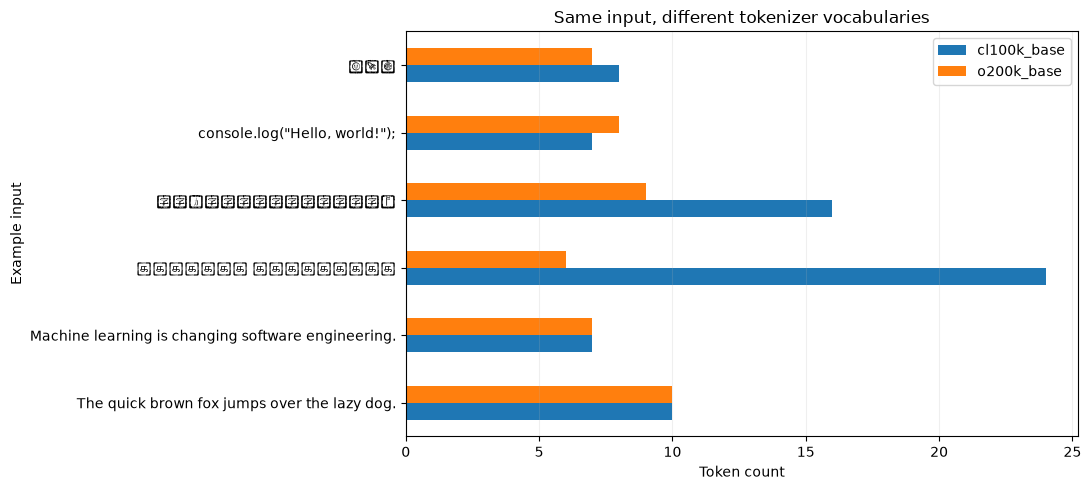

In [10]:
ax = comparison.set_index('sample')[list(encodings)].plot.barh(figsize=(11, 5))
ax.set_xlabel('Token count')
ax.set_ylabel('Example input')
ax.set_title('Same input, different tokenizer vocabularies')
ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()

**Interpret carefully:** A tokenizer with fewer tokens on one sample isn't automatically better in every dimension. It doesn't by itself establish lower model cost, higher quality, or faster inference. The model, pricing, processing efficiency, and use case also matter. For production token budgeting, select the **actual target model's** tokenizer.

## 06 — Build a visual token highlighter

Adjacent colored blocks represent consecutive token-byte pieces. For byte-safe rendering we show a UTF-8 preview, and retain the token's raw bytes as a hover tooltip. A `�` symbol can appear in an individual piece even if the full text round-trips correctly.

In [11]:
from html import escape

def show_token_pieces(text: str, encoding=enc):
    palette = ['#D9F3F0', '#FBE4C5', '#E6E0FA', '#DCEAFB', '#F8DDE8', '#E4F2CF']
    blocks = []
    for index, token_id in enumerate(encoding.encode(text)):
        raw = encoding.decode_single_token_bytes(token_id)
        preview = raw.decode('utf-8', errors='replace')
        # Preserve visible spaces in notebook HTML.
        label = escape(preview).replace(' ', '&nbsp;').replace('\n', '↵')
        tooltip = escape(f'id={token_id} | bytes={raw!r}', quote=True)
        blocks.append(f'<span title="{tooltip}" style="display:inline-block; padding:6px 9px; '
                      f'margin:3px; background:{palette[index % len(palette)]}; '
                      f'border-radius:7px; color:#1f2937; font-family:monospace">{label}</span>')
    display(HTML('<div style="line-height:2.6">' + ''.join(blocks) + '</div>'))
    print(f'{len(encoding.encode(text))} tokens | {encoding.name}')

show_token_pieces('Tokenization turns language into pieces. 🚀')

9 tokens | o200k_base


In [12]:
# Edit this example and rerun to investigate your own text.
YOUR_TEXT = 'Agentic AI systems need careful token budgeting.'
show_token_pieces(YOUR_TEXT)

9 tokens | o200k_base


## 07 — Build a reusable token analyzer

This is the beginning of a practical utility you can reuse when you start implementing RAG, agents, prompt templates, and LLM pipelines.

In [13]:
def analyze_text(text: str, encoding=enc) -> dict:
    """Analyze visible text locally; does not estimate API message overhead."""
    if not isinstance(text, str):
        raise TypeError('text must be a string')
    token_ids = encoding.encode(text)
    return {
        'encoding': encoding.name,
        'characters': len(text),
        'utf8_bytes': len(text.encode('utf-8')),
        'words_by_whitespace': len(text.split()),
        'token_count': len(token_ids),
        'token_ids': token_ids,
        'roundtrip_ok': encoding.decode(token_ids) == text,
    }

result = analyze_text('Build reliable AI agents, one token at a time.')
display(pd.DataFrame([result]).drop(columns='token_ids'))
print('Token IDs:', result['token_ids'])

,encoding,characters,utf8_bytes,words_by_whitespace,token_count,roundtrip_ok
0,o200k_base,46,46,9,11,True


Token IDs: [12893, 15048, 20837, 19297, 11, 1001, 6602, 540, 261, 1058, 13]


In [14]:
assert analyze_text('')['token_count'] == 0
assert analyze_text('வணக்கம் 🚀')['roundtrip_ok']
assert analyze_text('AI')['token_count'] >= 1
try:
    analyze_text(123)
except TypeError:
    print('Type validation passed.')
else:
    raise AssertionError('Expected a TypeError for non-string input')
print('All analyzer checks passed.')

Type validation passed.
All analyzer checks passed.


## 08 — Context windows: budget like an engineer

A model has a finite context capacity. In practice, budget for **instructions + conversation history + retrieved passages + tools / structured payloads + reserved output**, not only the latest user message.

```mermaid
flowchart LR
  A[System / developer instructions] --> T[Token budget]
  B[Conversation history] --> T
  C[Retrieved RAG passages] --> T
  D[Current user query] --> T
  E[Tool or schema payloads] --> T
  T --> F{Fits with output reserve?}
  F -->|Yes| G[Send request]
  F -->|No| H[Trim / summarize / retrieve less]
```

The following uses an **illustrative** capacity that you can configure. It does not assert the context window size of the selected model, and locally counted content tokens omit API protocol/message overhead.

In [15]:
def token_budget(parts: dict[str, str], capacity: int, output_reserve: int,
                 encoding=enc, overhead_reserve: int=0) -> pd.DataFrame:
    if capacity <= 0 or output_reserve < 0 or overhead_reserve < 0:
        raise ValueError('Capacity must be positive; reserves must be non-negative.')
    rows = [{'component': name, 'tokens': len(encoding.encode(value))}
            for name, value in parts.items()]
    used = sum(r['tokens'] for r in rows)
    rows += [
        {'component': 'OUTPUT RESERVE', 'tokens': output_reserve},
        {'component': 'OVERHEAD RESERVE (illustrative)', 'tokens': overhead_reserve},
    ]
    remaining = capacity - used - output_reserve - overhead_reserve
    rows.append({'component': 'REMAINING CAPACITY', 'tokens': remaining})
    return pd.DataFrame(rows)

parts = {
    'system_instructions': 'You are a concise AI engineering assistant.',
    'conversation_history': 'User: Explain RAG. Assistant: Retrieval-augmented generation adds evidence.',
    'retrieved_documents': ('Tokenization matters for retrieval chunking. ' * 80),
    'latest_user_question': 'How many retrieved passages can fit?',
}
CAPACITY = 4096  # demo assumption, NOT a claim about any named model
OUTPUT_RESERVE = 512
OVERHEAD_RESERVE = 128  # illustrative, NOT an exact protocol token calculation
budget_df = token_budget(parts, CAPACITY, OUTPUT_RESERVE, overhead_reserve=OVERHEAD_RESERVE)
display(budget_df)
remaining = int(budget_df.iloc[-1]['tokens'])
print('Budget status:', 'FITS' if remaining >= 0 else 'TOO LARGE')

,component,tokens
0,system_instructions,8
1,conversation_history,16
2,retrieved_documents,641
3,latest_user_question,7
4,OUTPUT RESERVE,512
5,OVERHEAD RESERVE (illustrative),128
6,REMAINING CAPACITY,2784


Budget status: FITS


### A practical mitigation ladder

1. Remove irrelevant history, but preserve critical requirements.
2. Retrieve fewer or better-ranked passages; deduplicate overlapping RAG chunks.
3. Summarize history, while keeping important facts and decisions accurately.
4. Use a suitable model with a sufficient context window.
5. Reserve output tokens and validate actual usage from the API.

**Important:** Simply taking the last `N` tokens can silently discard instructions or truncate a conversation mid-message. Production context packing should work on structured messages and prioritize essential context.

## 09 — Token economics & pricing (illustrative)

API pricing varies by model, date, token direction, caching, and other usage categories. **The numbers below are fictional teaching inputs, not live prices.** Always use the pricing page for your chosen model before making business decisions.

**Illustrative formula:**

\[
	ext{Estimated USD} = 
rac{T_{in}}{10^6} P_{in} + 
rac{T_{out}}{10^6} P_{out}
\]

This simplified model excludes cache discounts, multimodal payloads, reasoning details, tools, and service-specific billing rules.

In [16]:
def illustrative_cost(input_tokens: int, output_tokens: int,
                      usd_per_million_input: float, usd_per_million_output: float) -> float:
    if min(input_tokens, output_tokens) < 0:
        raise ValueError('Token counts must be non-negative')
    return (input_tokens / 1_000_000 * usd_per_million_input +
            output_tokens / 1_000_000 * usd_per_million_output)

# Fictional prices for learning ONLY.
EXAMPLE_INPUT_RATE = 1.00
EXAMPLE_OUTPUT_RATE = 4.00
traffic = pd.DataFrame([
    {'scenario': 'Tiny chat', 'input_tokens': 500, 'output_tokens': 150},
    {'scenario': 'RAG query', 'input_tokens': 6000, 'output_tokens': 500},
    {'scenario': 'Long agent run', 'input_tokens': 25000, 'output_tokens': 2000},
])
traffic['example_cost_usd'] = traffic.apply(
    lambda r: illustrative_cost(int(r.input_tokens), int(r.output_tokens),
                                EXAMPLE_INPUT_RATE, EXAMPLE_OUTPUT_RATE), axis=1)
display(traffic)

,scenario,input_tokens,output_tokens,example_cost_usd
0,Tiny chat,500,150,0.0011
1,RAG query,6000,500,0.0080
2,Long agent run,25000,2000,0.0330


### Why chat history grows your token budget

Let's reproduce the key lesson from the supplied reference: a follow-up question can include earlier user/assistant messages. More history generally means more input tokens. The estimate below counts **message content only**; real serialized API requests also include structure, roles, and potentially tool information.

In [17]:
conversation = [
    {'role': 'system', 'content': 'You are a helpful assistant.'},
    {'role': 'user', 'content': "Hi! I'm Ed!"},
    {'role': 'assistant', 'content': 'Hi Ed! How can I help?'},
    {'role': 'user', 'content': "What's my name?"},
]
content_token_counts = []
for turn in range(1, len(conversation) + 1):
    subset = conversation[:turn]
    content_token_counts.append(sum(len(enc.encode(m['content'])) for m in subset))
display(pd.DataFrame({'messages_included': range(1, len(conversation)+1),
                      'content_tokens_only': content_token_counts}))

,messages_included,content_tokens_only
0,1,6
1,2,11
2,3,19
3,4,23


## 10 — The illusion of memory: replaying context

This section follows the second half of the reference notebook, with an important modern clarification:

- A **standalone Chat Completions request** does not automatically remember earlier separate requests. Your application must supply the needed history.
- Modern APIs can also offer **server-managed conversation state**, such as the Responses API `previous_response_id` / Conversations API. These are conveniences for managing context, **not evidence of human-like persistent memory**. Prior context can still count toward usage/billing.
- Real product memory may additionally use durable storage, summaries, user preferences, retrieval, and explicit user controls. The reference's claim that *every* ChatGPT interaction simply resends the entire conversation is too broad to use as a universal architectural claim.

**Observe the two payloads below without making any paid API calls.**

In [18]:
without_history = [
    {'role': 'system', 'content': 'You are a helpful assistant.'},
    {'role': 'user', 'content': "What's my name?"},
]
with_history = [
    {'role': 'system', 'content': 'You are a helpful assistant.'},
    {'role': 'user', 'content': "Hi! I'm Ed!"},
    {'role': 'assistant', 'content': 'Hi Ed! How can I assist you today?'},
    {'role': 'user', 'content': "What's my name?"},
]

def print_messages(messages):
    for i, m in enumerate(messages, start=1):
        print(f"{i}. {m['role'].upper():9} | {m['content']}")

print('A — Without earlier introduction')
print_messages(without_history)
print('\nB — With conversation context')
print_messages(with_history)

A — Without earlier introduction
1. SYSTEM    | You are a helpful assistant.
2. USER      | What's my name?

B — With conversation context
1. SYSTEM    | You are a helpful assistant.
2. USER      | Hi! I'm Ed!
3. ASSISTANT | Hi Ed! How can I assist you today?
4. USER      | What's my name?


In [19]:
def content_tokens(messages, encoding=enc):
    return sum(len(encoding.encode(m['content'])) for m in messages)

print('A — Content tokens only:', content_tokens(without_history))
print('B — Content tokens only:', content_tokens(with_history))
print('Additional content tokens:', content_tokens(with_history) - content_tokens(without_history))
assert content_tokens(with_history) > content_tokens(without_history)

A — Content tokens only: 10
B — Content tokens only: 25
Additional content tokens: 15


**Expected reasoning (not an actual model result):** Payload B explicitly contains the name Ed, whereas A does not. Therefore B contains the evidence for answering the question. Whether a model answers correctly must be tested with a model call; the payload display itself does not demonstrate model behavior.

### A tiny local memory policy

For real systems, blindly replaying every turn forever is wasteful. The next lab is a **teaching-only message selector** which retains the system message and latest conversational turns under a content-token budget. It deliberately does **not** replace production-grade context management.

In [20]:
def select_recent_messages(messages: list[dict], max_content_tokens: int,
                           encoding=enc) -> list[dict]:
    """Teaching demo: keep initial system message + most recent messages within a content-only budget."""
    if max_content_tokens < 0:
        raise ValueError('Budget cannot be negative')
    system = messages[:1] if messages and messages[0].get('role') == 'system' else []
    latest = messages[len(system):]
    selected = list(system)
    current = content_tokens(selected, encoding)
    if current > max_content_tokens:
        raise ValueError('System instruction alone exceeds the content-token budget')
    tail = []
    for message in reversed(latest):
        size = len(encoding.encode(message['content']))
        if current + size > max_content_tokens:
            break
        tail.append(message)
        current += size
    return selected + list(reversed(tail))

selected = select_recent_messages(with_history, max_content_tokens=24)
print_messages(selected)
print('Selected content tokens:', content_tokens(selected))

1. SYSTEM    | You are a helpful assistant.
2. ASSISTANT | Hi Ed! How can I assist you today?
3. USER      | What's my name?
Selected content tokens: 20


**Why this is only a demo:** Token count for a complete API request is not just message content. This function can remove critical background facts; it is not guaranteed to preserve user/assistant turn pairs; and it does not account for tools, schemas, system/developer priority, or safety requirements. Better production designs keep structured history, durable facts, summaries, and testable retention rules.

## 11 — Optional: test real response usage with the OpenAI API

**Optional and billable.** Skip this section if you have no API credentials. It is not needed for any previous exercise.

Set `OPENAI_API_KEY` securely in a local `.env` file (excluded by `.gitignore`), then install the `openai` and `python-dotenv` packages. The code uses an explicit `RUN_LIVE_API = False` guard.

This example uses Chat Completions to stay close to the provided reference; for new applications also learn the Responses API and its conversation-state features. The model ID is an example and must be available to your account.

In [21]:
RUN_LIVE_API = False  # Change to True only if you intend to make a billable request.

if RUN_LIVE_API:
    import os
    from dotenv import load_dotenv
    from openai import OpenAI

    load_dotenv()
    if not os.getenv('OPENAI_API_KEY'):
        raise RuntimeError('OPENAI_API_KEY not found. Add it to your local, gitignored .env.')

    client = OpenAI()
    response = client.chat.completions.create(
        model='gpt-4.1-mini',
        messages=with_history,
    )
    print('Model said:', response.choices[0].message.content)
    print('Actual API usage:', response.usage)
else:
    print('Live API skipped: RUN_LIVE_API=False. All previous labs work locally.')

Live API skipped: RUN_LIVE_API=False. All previous labs work locally.


### Compare estimate vs measured usage

When a live call is executed, `response.usage` exposes request usage counters. Compare its input usage to your **content-only** estimate. The difference can arise from roles, message framing, model- or API-specific serialization, and other request fields. Never treat an ad hoc fixed per-message count as exact for all APIs/models.

## 12 — Mini project: a reusable prompt budget checker

Create a small preflight utility to check whether plain-text components fit a user-specified budget. It doesn't make network calls and intentionally reports **estimate only**.

In [22]:
def preflight_prompt(system: str, history: list[str], retrieved_chunks: list[str],
                     question: str, capacity: int, output_reserve: int,
                     overhead_reserve: int = 128, encoding=enc) -> dict:
    content = {
        'system': system,
        'history': '\n'.join(history),
        'retrieval': '\n\n'.join(retrieved_chunks),
        'question': question,
    }
    content_counts = {key: len(encoding.encode(value)) for key, value in content.items()}
    used = sum(content_counts.values()) + output_reserve + overhead_reserve
    return {
        'encoding': encoding.name,
        'content_token_breakdown': content_counts,
        'capacity_assumption': capacity,
        'output_reserve': output_reserve,
        'overhead_reserve_assumption': overhead_reserve,
        'estimated_total': used,
        'remaining': capacity - used,
        'fits_estimate': used <= capacity,
    }

report = preflight_prompt(
    system='You are an AI tutor. Cite retrieved evidence.',
    history=['User asked about tokenization.', 'Assistant explained token IDs.'],
    retrieved_chunks=['Tokens are units for input and output.', 'Context space is finite.'],
    question='How can I manage prompt size?',
    capacity=2048,
    output_reserve=300,
)
display(pd.DataFrame([{'metric': k, 'value': v} for k, v in report.items()]))
assert report['fits_estimate']

,metric,value
0,encoding,o200k_base
1,content_token_breakdown,"{'system': 10, 'history': 11, 'retrieval': 13,..."
2,capacity_assumption,2048
3,output_reserve,300
4,overhead_reserve_assumption,128
5,estimated_total,469
6,remaining,1579
7,fits_estimate,True


## 🧪 Challenge zone — practice like an AI engineer

**Challenge 1 — Prediction:** Predict whether a piece of Tamil text will have the same token count under `cl100k_base` and `o200k_base`. Verify with the code, then explain the result.

**Challenge 2 — Code vs prose:** Compare token counts for 100 lines of Python and 100 plain-English sentences. Is “one token equals one word” a reliable estimate?

**Challenge 3 — Budget pressure:** Repeat the mini-project with a smaller assumed capacity and more retrieved chunks. Implement a policy that removes low-priority retrieved chunks *without* discarding the question or system instruction.

**Challenge 4 — History test:** Explain why `without_history` cannot reliably answer Ed’s name, but `with_history` can. How might summary memory or server-managed conversation state change your implementation?

**Challenge 5 — Production thinking:** List at least five reasons the true API input token count can differ from a simple `sum(len(enc.encode(content)))` estimate.

**Stretch project:** Wrap the analyzer in a small Gradio or Streamlit UI with a tokenizer selector, multilingual examples, and a configurable context budget. Build the interface in a later lesson; this notebook provides its computation core.

In [23]:
# FINAL SELF-CHECK: repeatable assertions, no network or API key needed.
assert enc.decode(enc.encode('Hello, AI Engineer!')) == 'Hello, AI Engineer!'
assert enc.decode(enc.encode('தமிழ் 🚀')) == 'தமிழ் 🚀'
assert analyze_text('abc')['token_count'] == len(enc.encode('abc'))
assert content_tokens(with_history) > content_tokens(without_history)
assert report['estimated_total'] == report['capacity_assumption'] - report['remaining']
assert select_recent_messages(with_history, 1000) == with_history
print('✅ Day 02 self-checks passed. Congratulations!')

✅ Day 02 self-checks passed. Congratulations!


## ✅ Day 02 — Takeaways

| Concept | What you should remember |
|---|---|
| Token ≠ word | Segment boundaries come from a tokenizer's rules and vocabulary |
| IDs are encoding-specific | Token IDs should always be interpreted with their matching encoding |
| UTF-8 matters | Single token bytes may not decode into a whole readable character |
| Model families differ | Compare encodings, but benchmark with the target model |
| Context is finite | Reserve space for output, system instructions, history, retrieval and overhead |
| Billing uses actual usage | Local content counts are estimates, not guaranteed API totals |
| “Memory” needs context | Chat Completions does not remember separate calls unless context is supplied |
| Modern conversation state | APIs can help manage history, but prior context may still count toward usage |

### What comes next?

**Day 03 suggestion — Embeddings & Semantic Similarity:** how tokens relate to embeddings, vector similarity, retrieval, and the foundation of RAG. (Plan only; not included here.)

---

### 📚 Reference & verification links

- [OpenAI Cookbook — Counting tokens with tiktoken](https://cookbook.openai.com/examples/how_to_count_tokens_with_tiktoken)
- [tiktoken — Official repository](https://github.com/openai/tiktoken)
- [OpenAI — Understanding tokens](https://help.openai.com/en/articles/4936856-understanding-and-counting-tokens)
- [OpenAI API — Conversation state](https://developers.openai.com/api/docs/guides/conversation-state)
- [OpenAI API — Migrating to Responses](https://developers.openai.com/api/docs/guides/migrate-to-responses)

*Source inspiration: user-provided `day4.ipynb`. Updated explanations distinguish manually replayed context from modern server-managed state. Token counts and examples are computed dynamically; price inputs and illustrative capacity settings are intentionally not presented as current API specifications.*

<div align="center"><b>AI ENGINEERING MASTERCLASS · CORE TRACK · DAY 02 COMPLETE</b></div>